# 현실의 데이터 24: 부품 외관 검사: 불량 사진 없이 불량 찾기

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/notebooks/datashop/24_visual_inspection.ipynb)

**분야**: 제조 &nbsp;|&nbsp; **이 분야에서 먼저 보는 문제**: 비전 검사 (머신 비전) · 이상 탐지 (anomaly detection) · 정상만 있는 학습 데이터

> 금속 너트 사진. 학습용은 정상 220장뿐이다. 처음 보는 불량을 골라낼 수 있을까?

**데이터**: MVTec AD (금속 너트) (약 170MB (사진 335장, 700×700)). MVTec Software GmbH 가 공개한 공장 부품 · 표면 15종의 이상 탐지 데이터 중 금속 너트 (Bergmann et al., CVPR 2019). Hugging Face 사본 (TheoM55/mvtec_all_objects_split) 에서 받는다. 라이선스 CC BY-NC-SA 4.0 (비상업 용도만).

산업 현장의 문제와 닮은 공개 데이터다. 데이터를 열어 보고, 아래 예시처럼 문제 하나를 정해 기준선과 비교한 뒤, 맨 끝의 **나의 다섯 칸** 을 채운다 (1주 2차시 '문제 정형화와 평가지표').

| 칸 | 이 노트북의 예시 |
|---|---|
| ① 한 행 | 부품 사진 한 장 |
| ② 입력 X | 사진 (학습에는 정상 사진만) |
| ③ 출력 y | 이상 점수 (높을수록 불량 같음) → 기준을 넘으면 불량 |
| ④ 평가지표 | ROC-AUC, '불량 95% 를 잡을 때 정상을 몇 % 버리나' |
| ⑤ 기준선 | 무작위 점수 (AUC 0.5) · 픽셀 그대로 비교 |

**논문 · 출처** (직접 열어 보자: 이 데이터를 누가, 왜, 어떻게 만들었나):
- [Bergmann et al. (2019) MVTec AD: A Comprehensive Real-World Dataset for Unsupervised Anomaly Detection, CVPR](https://doi.org/10.1109/CVPR.2019.00982)
- [Roth et al. (2022) Towards Total Recall in Industrial Anomaly Detection (PatchCore), CVPR](https://arxiv.org/abs/2106.08265)

In [1]:
import io, os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(url, path):
    """Download url to path once (skip if it already exists)"""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    if not os.path.exists(path):
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (ML course data shop)"})
        with urllib.request.urlopen(req, timeout=600) as r, open(path, "wb") as f:
            f.write(r.read())
    return path

## 입장: 데이터 받기

공장에서는 불량이 아주 드물고, 종류도 미리 다 알 수 없다. 그래서 이 데이터는 **학습용에 정상 사진만** 있다. 시험용에는 정상 22장과 불량 4종류 (휨 · 색 · 뒤집힘 · 긁힘) 가 섞여 있다.

parquet 파일 두 개 (학습 · 시험) 에 사진 (png 바이트) 과 라벨이 들어 있다. 라이선스: CC BY-NC-SA 4.0 (수업 · 연구 같은 비상업 용도만).

In [2]:
from PIL import Image

BASE = "https://huggingface.co/datasets/TheoM55/mvtec_all_objects_split/resolve/main/data/"
train = pd.read_parquet(download(BASE + "metal_nut.train-00000-of-00001.parquet", "data/mvtec/metal_nut.train.parquet"))
test = pd.read_parquet(download(BASE + "metal_nut.test-00000-of-00001.parquet", "data/mvtec/metal_nut.test.parquet"))

def load_images(df, size):
    """Decode the png bytes in df['image_path'] into an array (n, size, size, 3) with values 0..1"""
    return np.stack([np.asarray(Image.open(io.BytesIO(b["bytes"])).convert("RGB").resize((size, size)), dtype=np.float32) / 255
                     for b in df["image_path"]])

print("train:", train["defect"].value_counts().to_dict())
print("test :", test["defect"].value_counts().to_dict())

train: {'good': 220}
test : {'bent': 25, 'flip': 23, 'scratch': 23, 'color': 22, 'good': 22}


## 열어 보기

정상 너트와 불량 4종류를 나란히 보자. 사람 눈에도 바로 보이는 것 (휨) 과 잘 안 보이는 것 (긁힘) 이 있다. **뒤집힘 (flip)** 은 흠집이 아니라 너트가 뒤집혀 놓인 것이다.

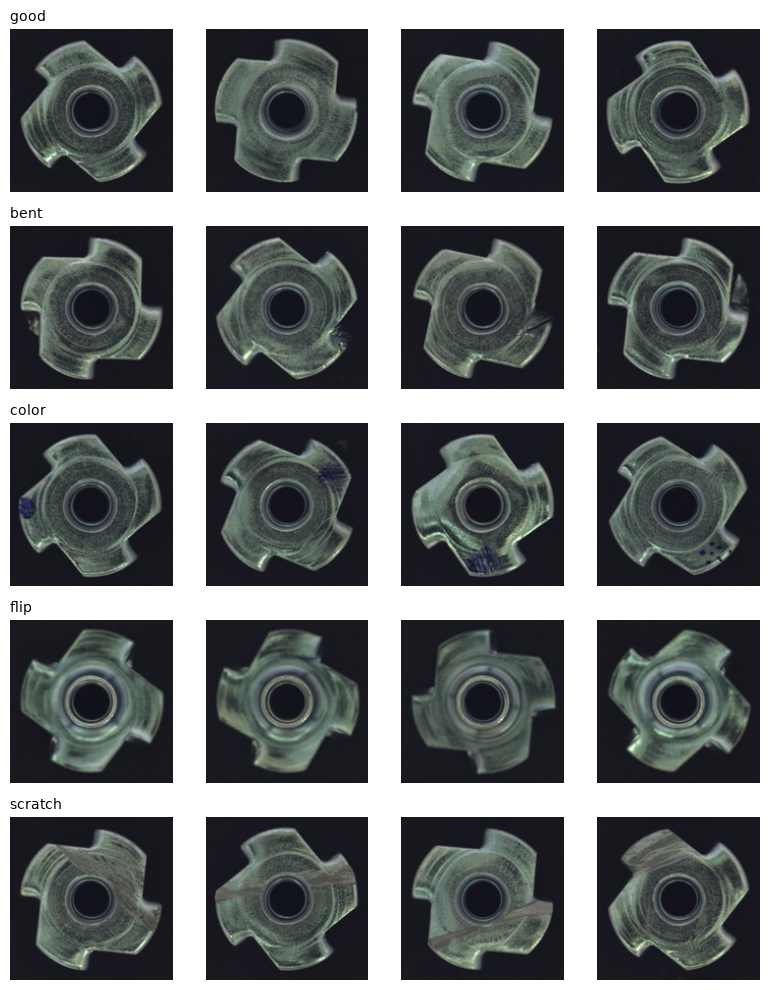

In [3]:
def show_examples(df, size=160):
    """One row per defect kind, 4 photos each"""
    kinds = ["good"] + sorted(k for k in df["defect"].unique() if k != "good")
    fig, axs = plt.subplots(len(kinds), 4, figsize=(8, 2 * len(kinds)))
    for r, k in enumerate(kinds):
        imgs = load_images(df[df["defect"] == k].head(4), size)
        for c in range(4):
            axs[r, c].imshow(imgs[c]); axs[r, c].axis("off")
        axs[r, 0].set_title(k, loc="left", fontsize=10)
    plt.tight_layout(); plt.show()

show_examples(test)

## 문제 하나 골라 보기: 정상 사진만 보고 이상 점수 매기기

분류기를 학습할 수 없다 (불량 사진이 없으니까). 대신 **'정상과 얼마나 다른가'** 를 점수로 만든다.
- 기준선 1: 무작위 점수 → AUC 0.5
- 기준선 2: 사진을 64×64 픽셀로 줄여 PCA (정상 사진으로 학습) → 다시 그렸을 때 틀린 정도가 점수
- 모델: ImageNet 으로 미리 학습한 ResNet-18 (10주차) 의 중간 특징 → 가장 가까운 정상 사진 3장까지의 거리가 점수

평가지표 두 가지: ROC-AUC (기준을 정하지 않은 점수의 실력), 그리고 현장에서 묻는 질문 **'불량을 95% 잡으려면 정상을 몇 % 나 불량으로 버려야 하나'**.

In [4]:
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score

def false_alarm_at_recall(y, score, recall=0.95):
    """Share of good parts rejected when the threshold is set to catch `recall` of the defects"""
    thr = np.quantile(score[y == 1], 1 - recall)
    return np.mean(score[y == 0] >= thr)

def report(name, y, score, defect):
    per = {k: round(roc_auc_score(y[(defect == k) | (y == 0)], score[(defect == k) | (y == 0)]), 2) for k in sorted(set(defect[y == 1]))}
    print(f"{name:28s} AUC {roc_auc_score(y, score):.3f}   good parts rejected at 95% recall {false_alarm_at_recall(y, score):.0%}   AUC per defect {per}")

y, defect = test["label"].values, test["defect"].values
rng = np.random.default_rng(0)
draws = [rng.random(len(y)) for _ in range(500)]          # one random draw is noisy with 115 photos, so average 500
print(f"{'random score (500 draws)':28s} AUC {np.mean([roc_auc_score(y, s) for s in draws]):.3f}   good parts rejected at 95% recall {np.mean([false_alarm_at_recall(y, s) for s in draws]):.0%}")

A, B = load_images(train, 64).reshape(len(train), -1), load_images(test, 64).reshape(len(test), -1)
pca = PCA(20, random_state=0).fit(A)
report("pixels + PCA reconstruction", y, ((B - pca.inverse_transform(pca.transform(B))) ** 2).mean(1), defect)

random score (500 draws)     AUC 0.501   good parts rejected at 95% recall 94%


pixels + PCA reconstruction  AUC 0.586   good parts rejected at 95% recall 77%   AUC per defect {'bent': 0.45, 'color': 0.46, 'flip': 1.0, 'scratch': 0.43}


In [5]:
import torch, torchvision

def resnet_features(images, model, batch=32):
    """Average-pooled layer2 + layer3 features of an ImageNet ResNet-18 for images (n, 224, 224, 3)"""
    mean, std = np.array([0.485, 0.456, 0.406]), np.array([0.229, 0.224, 0.225])
    x = torch.tensor(((images - mean) / std).transpose(0, 3, 1, 2), dtype=torch.float32)
    out = []
    with torch.no_grad():
        for i in range(0, len(x), batch):
            h = model.maxpool(model.relu(model.bn1(model.conv1(x[i:i + batch]))))
            h2 = model.layer2(model.layer1(h)); h3 = model.layer3(h2)
            out.append(torch.cat([h2.mean((2, 3)), h3.mean((2, 3))], 1).numpy())
    return np.concatenate(out)

def knn_score(train_feats, test_feats, k=3):
    """Mean distance to the k nearest normal (training) images"""
    d = np.sqrt(((test_feats[:, None] - train_feats[None]) ** 2).sum(2))
    return np.sort(d, 1)[:, :k].mean(1)

resnet = torchvision.models.resnet18(weights="IMAGENET1K_V1").eval()
Ftr, Fte = resnet_features(load_images(train, 224), resnet), resnet_features(load_images(test, 224), resnet)
report("ResNet-18 features + 3-NN", y, knn_score(Ftr, Fte), defect)

ResNet-18 features + 3-NN    AUC 0.838   good parts rejected at 95% recall 73%   AUC per defect {'bent': 0.77, 'color': 0.71, 'flip': 1.0, 'scratch': 0.87}


**관찰**: 픽셀을 그대로 비교하면 동전 던지기와 별 차이가 없다 (뒤집힌 너트만 잘 잡는다: 사진 전체가 달라 보이니까). 너트가 조금만 돌아가 있어도 픽셀이 전부 달라지기 때문이다. 고양이 · 자동차 사진으로 미리 학습한 신경망의 특징을 쓰면 **너트를 한 번도 배운 적이 없는데도** AUC 가 0.84 로 오른다. 그래도 불량을 95% 잡으려면 정상 너트를 넷 중 셋쯤 버려야 한다. 현장에서는 이 '버리는 정상품' 이 곧 비용이라서, 기준을 어디에 둘지가 문제 정의의 일부다. 휨 · 색 불량이 가장 어렵다.

## 다른 문제로 바꿔 보기

- **어디가 불량인가**: 사진 전체 점수 대신 칸 (patch) 마다 점수를 내면 불량 위치 지도가 된다. 이 데이터에는 불량 위치 마스크 (`mask_path`) 도 들어 있다.
- **다른 부품**: 같은 저장소에 병 · 나사 · 알약 · 케이블 · 직물 등 14종이 더 있다 (`metal_nut` 대신 `screw` 등).
- **현실의 비율**: 실제 라인의 불량률은 0.1% 쯤이다. 시험 데이터의 불량 비율 (81%) 을 그렇게 바꾸면 정밀도는 어떻게 될까?

### 나의 다섯 칸

아래 표를 직접 채워 보자. 위의 예시와 다르게 정해도 된다.

| 칸 | 내가 정한 것 |
|---|---|
| ① 한 행은 무엇? | |
| ② 입력 X (예측할 때 알 수 있는 것만) | |
| ③ 출력 y | |
| ④ 평가지표 | |
| ⑤ 기준선 | |